# Objetivo 2 · Actividad 2 — Análisis exploratorio de ofertas laborales (EDA)

**Fuente vigente:** `Obj2/Act. 1/Ofertas_Normalizadas_ESCO_diccionario.csv` · **Unidad de análisis:** vacante laboral (`job_id`).

Notebook complementario a `EDA_Perfiles.ipynb`. Se analiza el conjunto de vacantes laborales seleccionado para el estudio minero chileno, **sin restringirlo geográficamente a Coquimbo ni por trayectoria profesional**. La fuente académica corresponde a otro universo y no se fusiona aquí.

**Alcance:** controles de integridad; calidad de normalización ESCO; distribuciones por empresa, ubicación declarada, disciplina y trayectoria; experiencia; frecuencia de competencias por **URI**; análisis descriptivo por grupos y exploración individual. **No** se calculan reglas Apriori ni se interpreta frecuencia como cobertura curricular. Ninguna asignación automatizada se considera confirmación humana de pertinencia semántica.

**Importante:** las vacantes sin competencias ESCO seleccionadas se clasifican como *normalización incompleta* y **no** como vacantes sin demanda técnica.

## 1. Carga de datos y configuración

Se lee **directamente** el CSV normalizado vigente, sin generar un archivo «limpio» ni descartar `Estado_ESCO`, `Modelo_ESCO` o las evidencias. El código encuentra la fuente tanto si se ejecuta desde `Obj2/Act. 2` como desde la raíz `DESARROLLO`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 105)

NOMBRE_FUENTE = 'Ofertas_Normalizadas_ESCO_diccionario.csv'
RUTAS_CANDIDATAS = [
    Path('../Act. 1') / NOMBRE_FUENTE,
    Path('Obj2/Act. 1') / NOMBRE_FUENTE,
    Path('DESARROLLO/Obj2/Act. 1') / NOMBRE_FUENTE,
    Path(NOMBRE_FUENTE),
]
RUTA_FUENTE = next((p.resolve() for p in RUTAS_CANDIDATAS if p.is_file()), None)
if RUTA_FUENTE is None:
    raise FileNotFoundError(
        'No se encontró el CSV ESCO laboral vigente. Abre este notebook desde Obj2/Act. 2 '
        'y comprueba que existe en ../Act. 1/Ofertas_Normalizadas_ESCO_diccionario.csv. '
        f'Rutas comprobadas: {RUTAS_CANDIDATAS}'
    )

ofertas = pd.read_csv(RUTA_FUENTE, sep=';', encoding='utf-8-sig', dtype=str).fillna('')
print('Archivo:', RUTA_FUENTE)
print('Dimensiones:', ofertas.shape)
print('Columnas:', ofertas.columns.tolist())
display(ofertas[['job_id', 'titulo', 'empresa', 'categoria_trayectoria', 'Estado_ESCO']].head(7))

Archivo: /mnt/data/_validacion_eda_ofertas/DESARROLLO/Obj2/Act. 1/Ofertas_Normalizadas_ESCO_diccionario.csv
Dimensiones: (242, 17)
Columnas: ['job_id', 'titulo', 'empresa', 'ubicacion', 'disciplina_detectada', 'categoria_trayectoria', 'anios_experiencia', 'habilidades_crudas', 'texto_bruto', 'SHA256_oferta_fuente', 'Competencias_ESCO_Extraidas', 'Competencias_ESCO_URI', 'Competencias_ESCO_Detalle', 'Candidatos_ESCO', 'Estado_ESCO', 'Modelo_ESCO', 'SHA256_catalogo_ESCO']


,job_id,titulo,empresa,categoria_trayectoria,Estado_ESCO
0,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,SENIOR_LIDERAZGO,Catalogo_verificado_revision_pendiente
1,2fec54987f7dfcc4,Ingeniero de Integridad,SGS,JUNIOR_TRAINEE,Catalogo_verificado_revision_pendiente
2,ed4c03cdd32d6820,Ingeniero de proyecto,SQM,JUNIOR_TRAINEE,Catalogo_verificado_revision_pendiente
3,35ebf411ee1348b7,Ingeniero Geotécnico Junior (0-4 años de experiencia),Stantec,JUNIOR_TRAINEE,Catalogo_verificado_revision_pendiente
4,7ffa0f30fe68a741,Puestos vacantes: Ingeniera(o) Planificacion Perforacion y Tronadura (20686),Antofagasta Minerals,SENIOR_LIDERAZGO,Catalogo_verificado_revision_pendiente
5,b5c228b6f3367f0b,CL - INGENIERO DE PROCESO I,Sherwin-Williams,JUNIOR_TRAINEE,Catalogo_verificado_revision_pendiente
6,d1eb46bda5cfe696,DW/ Programador Planificador/ Ingeniero Mecánico /Minera Los Bronces,ReliX Water,SENIOR_LIDERAZGO,Catalogo_verificado_revision_pendiente


## 2. Integridad y estructuración de las competencias ESCO

Una competencia es un concepto identificado por su **URI**, no por su etiqueta textual. Se leen las listas JSON de `Competencias_ESCO_URI` y `Competencias_ESCO_Detalle` para evitar separar incorrectamente etiquetas oficiales que contienen comas. Se conserva una tabla larga de asignaciones para las frecuencias y otra tabla de vacantes para los denominadores.

In [2]:
COLUMNAS_REQUERIDAS = {
    'job_id', 'titulo', 'empresa', 'ubicacion', 'disciplina_detectada',
    'categoria_trayectoria', 'anios_experiencia', 'habilidades_crudas',
    'texto_bruto', 'Competencias_ESCO_URI', 'Competencias_ESCO_Detalle',
    'Estado_ESCO', 'Modelo_ESCO'
}
faltantes = COLUMNAS_REQUERIDAS - set(ofertas.columns)
if faltantes:
    raise ValueError(f'Faltan columnas requeridas: {sorted(faltantes)}')
if ofertas['job_id'].str.strip().eq('').any():
    raise ValueError('Hay vacantes sin job_id')
if ofertas['job_id'].duplicated().any():
    raise ValueError('Hay job_id duplicados; el EDA requiere una fila por vacante')

def lista_json(valor, campo, identificador):
    try:
        resultado = json.loads(valor if str(valor).strip() else '[]')
    except (ValueError, TypeError) as exc:
        raise ValueError(f'JSON incorrecto en {campo} para job_id={identificador}') from exc
    if not isinstance(resultado, list):
        raise ValueError(f'{campo} no contiene una lista: job_id={identificador}')
    return resultado

registros = []
conteos = []
for _, fila in ofertas.iterrows():
    job_id = fila['job_id']
    uris = lista_json(fila['Competencias_ESCO_URI'], 'Competencias_ESCO_URI', job_id)
    detalles = lista_json(fila['Competencias_ESCO_Detalle'], 'Competencias_ESCO_Detalle', job_id)
    if uris != [d.get('uri') for d in detalles]:
        raise ValueError(f'Inconsistencia entre URI y detalle: job_id={job_id}')
    if len(uris) != len(set(uris)):
        raise ValueError(f'URI repetido dentro de la vacante: job_id={job_id}')
    conteos.append(len(uris))
    for d in detalles:
        if not (str(d.get('uri', '')).strip() and str(d.get('etiqueta', '')).strip()):
            raise ValueError(f'Detalle sin URI o etiqueta: job_id={job_id}')
        registros.append({
            'job_id': job_id, 'titulo': fila['titulo'], 'empresa': fila['empresa'],
            'ubicacion': fila['ubicacion'],
            'disciplina_detectada': fila['disciplina_detectada'],
            'categoria_trayectoria': fila['categoria_trayectoria'],
            'URI': d['uri'], 'Competencia': d['etiqueta'],
            'Evidencia': d.get('evidencia', ''),
        })

base = ofertas.copy()
base['N_Competencias'] = conteos
base['Estado_Analitico'] = np.where(base['N_Competencias'] > 0,
                                      'Con selección ESCO', 'Normalización incompleta')
base['Anios_Experiencia_Num'] = pd.to_numeric(
    base['anios_experiencia'].replace('', np.nan), errors='coerce'
)
competencias = pd.DataFrame(registros, columns=[
    'job_id','titulo','empresa','ubicacion','disciplina_detectada',
    'categoria_trayectoria','URI','Competencia','Evidencia'
])

print('Vacantes:', len(base))
print('Vacantes con competencias ESCO:', (base['N_Competencias'] > 0).sum())
print('Normalización incompleta:', (base['N_Competencias'] == 0).sum())
print('Asignaciones:', len(competencias))
print('URI distintos:', competencias['URI'].nunique())
print('Duplicados job_id/URI:', competencias.duplicated(['job_id','URI']).sum())
display(competencias.head(8))

Vacantes: 242
Vacantes con competencias ESCO: 228
Normalización incompleta: 14
Asignaciones: 1341
URI distintos: 446
Duplicados job_id/URI: 0


,job_id,titulo,empresa,ubicacion,disciplina_detectada,categoria_trayectoria,URI,Competencia,Evidencia
0,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/1be014ca-6909-497a-95fc-426ef9945583,insertar cargas en pozos de perforación,Supervisar la correcta ejecución del proceso de carguío de explosivo y tronadura según los diseños y ...
1,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/c42a92b2-a802-4cf6-a645-3904004bbdbe,detonar explosivos en condiciones seguras,"Verificar el cumplimiento de los procedimientos de seguridad antes, durante y después de la tronadura."
2,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/e9867780-9584-43a9-af10-8eb730b525cc,examinar zonas tras la detonación de explosivos,Realizar inspecciones post-tronadura para evaluar resultados y proponer mejoras.
3,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/ab6265f2-a9bf-49e8-a9a5-67cbab4de38b,gestionar el inventario,"Llevar el control del consumo de explosivos, accesorios y materiales auxiliares."
4,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/d0f2f8a7-d935-4a6d-8e54-dcc3e5e2cbeb,presentar informes,Elaborar informes diarios de operación de tronadura y cumplimiento de plan.
5,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/56fa904b-eb1c-4f34-a671-8c5dc6af6de1,colaborar con profesionales de la geología,Coordinar con el área de geología los tiempos de operación de muestreo para liberación de áreas de tr...
6,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/3cd35f5d-ce6d-4f14-9a09-53d7a28d834c,mantener la relación con los proveedores,Asegurar la disponibilidad de materiales explosivos y equipos necesarios con proveedor de explosivo d...
7,afe7fc2465345541,Puestos vacantes: Supervisora(or) Tronadura (20684),Antofagasta Minerals,"Gran Santiago, Región Metropolitana de Santiago, Chile",INGENIERÍA CIVIL DE MINAS,SENIOR_LIDERAZGO,http://data.europa.eu/esco/skill/9d59f4e5-20a5-428e-b8b3-645043500457,crear un ambiente de trabajo de mejora continua,Realizar inspecciones post-tronadura para evaluar resultados y proponer mejoras.


## 3. Calidad de los registros y estados de normalización

Se distinguen tres situaciones: vacantes con asignaciones sin descartes (`Catalogo_verificado...`), vacantes con algunas asignaciones y observaciones, y vacantes cuya normalización quedó incompleta. Los estados originales **no se modifican**.

In [3]:
print('Total de vacantes:', len(base))
print('Empresas diferentes (etiqueta exacta):', base['empresa'].nunique())
print('Ubicaciones distintas (texto declarado):', base['ubicacion'].nunique())
print('Etiquetas distintas de disciplina:', base['disciplina_detectada'].nunique())
print('job_id duplicados:', base.duplicated('job_id').sum())

campos_interes = [
    'job_id','titulo','empresa','ubicacion','disciplina_detectada',
    'categoria_trayectoria','anios_experiencia','habilidades_crudas',
    'texto_bruto','Competencias_ESCO_URI','Estado_ESCO'
]
control_vacios = pd.DataFrame({
    'Campo': campos_interes,
    'Vacios (cadena o nulo)': [int(base[c].astype(str).str.strip().eq('').sum()) for c in campos_interes],
})
display(control_vacios)

estados = base.groupby(['Estado_Analitico','Estado_ESCO'], dropna=False).size().reset_index(name='Vacantes')
display(estados.sort_values('Vacantes', ascending=False))

pendientes = base.loc[base['N_Competencias'].eq(0),
    ['job_id','titulo','empresa','disciplina_detectada','categoria_trayectoria','Estado_ESCO']]
print('Vacantes con normalización incompleta:', len(pendientes))
display(pendientes.reset_index(drop=True))
print('Nota: estas vacantes pueden describir habilidades técnicas no seleccionadas por el normalizador.')

Total de vacantes: 242
Empresas diferentes (etiqueta exacta): 128
Ubicaciones distintas (texto declarado): 38
Etiquetas distintas de disciplina: 60
job_id duplicados: 0


,Campo,Vacios (cadena o nulo)
0,job_id,0
1,titulo,0
2,empresa,0
3,ubicacion,0
4,disciplina_detectada,0
5,categoria_trayectoria,0
6,anios_experiencia,5
7,habilidades_crudas,1
8,texto_bruto,0
9,Competencias_ESCO_URI,0


,Estado_Analitico,Estado_ESCO,Vacantes
0,Con selección ESCO,Catalogo_verificado_revision_pendiente,218
5,Normalización incompleta,Revisar (Sin competencias justificadas),14
1,Con selección ESCO,Revisar (1 descartes),6
3,Con selección ESCO,Revisar (3 descartes),2
2,Con selección ESCO,Revisar (2 descartes),1
4,Con selección ESCO,Revisar (4 descartes),1


Vacantes con normalización incompleta: 14


,job_id,titulo,empresa,disciplina_detectada,categoria_trayectoria,Estado_ESCO
0,a32355b4640b2f05,Alumno (a) en Practica,Kinross Gold Corporation,INGENIERÍA CIVIL METALÚRGICA / INGENIERÍA METALÚRGICA / INGENIERÍA DE PROCESOS,PRACTICA_MEMORIA,Revisar (Sin competencias justificadas)
1,b3a80b97c410e6f6,Practicas y Memorias 2027,Lundin Mining Corporation,Ingeniería Civil de Minas / Ingeniería en Minas,PRACTICA_MEMORIA,Revisar (Sin competencias justificadas)
2,1cf991a582d55258,Energy4Talent Trainee 2027 - Chile,AES Andes,INGENIERÍA EN ENERGÍA,JUNIOR_TRAINEE,Revisar (Sin competencias justificadas)
3,919a417a600737a2,Proyectista Junior COD 267196 – 07,R&Q Ingeniería,INGENIERÍA CIVIL / INGENIERÍA CIVIL MECÁNICA,JUNIOR_TRAINEE,Revisar (Sin competencias justificadas)
4,7c15107a375b3800,Metalúrgico,Buffer,INGENIERÍA CIVIL METALÚRGICA / INGENIERÍA METALÚRGICA / INGENIERÍA DE PROCESOS,SENIOR_LIDERAZGO,Revisar (Sin competencias justificadas)
5,351ceba78a7cadee,INGENIERO PROGRAMADOR DE PROYECTOS,SKM,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA CIVIL,SEMI_SENIOR,Revisar (Sin competencias justificadas)
6,93557398fb1d673d,"Ingeniero P&C, Primavera P6 - Proyecto transporte Subterráneo, Cerrillos",DRS Ingeniería y Gestión,INGENIERÍA CIVIL,JUNIOR_TRAINEE,Revisar (Sin competencias justificadas)
7,db069fcaafa80e44,Ingeniero/a Procesos Sr,Servicios Procure,INGENIERÍA CIVIL QUÍMICA / INGENIERÍA EN PROCESOS,SENIOR_LIDERAZGO,Revisar (Sin competencias justificadas)
8,ec343665bf9cc4bb,Analista de Inteligencia de Negocios,LarrainVial,INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,JUNIOR_TRAINEE,Revisar (Sin competencias justificadas)
9,cf33a27321ad8d52,Business Intelligence Engineer,Sur Global,INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,SENIOR_LIDERAZGO,Revisar (Sin competencias justificadas)


Nota: estas vacantes pueden describir habilidades técnicas no seleccionadas por el normalizador.


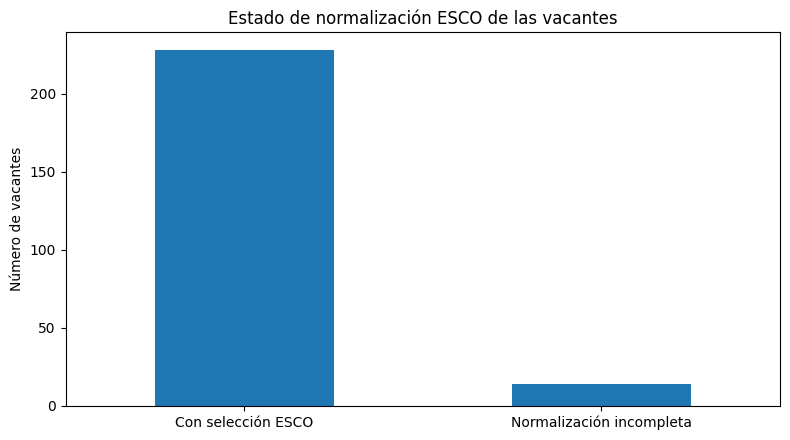

In [4]:
conteo_estado = base['Estado_Analitico'].value_counts().reindex(
    ['Con selección ESCO','Normalización incompleta'], fill_value=0)
plt.figure(figsize=(8, 4.5))
conteo_estado.plot(kind='bar')
plt.title('Estado de normalización ESCO de las vacantes')
plt.ylabel('Número de vacantes')
plt.xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Cantidad de competencias ESCO por vacante

Se cuentan conceptos **URI distintos por vacante**. El máximo configurado en la versión laboral es de ocho; alcanzar ese límite implica posible truncamiento, **no demuestra** que existan otras competencias omitidas en esa vacante.

Descripción de competencias por vacante (incluye las 14 incompletas):


,N_Competencias
count,242.000000
mean,5.541322
std,2.083413
min,0.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,8.000000


Descripción únicamente para vacantes normalizadas:


,N_Competencias
count,228.000000
mean,5.881579
std,1.611909
min,1.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,8.000000


,Competencias,Vacantes
0,0,14
1,1,2
2,2,4
3,3,9
4,4,29
5,5,44
6,6,67
7,7,18
8,8,55


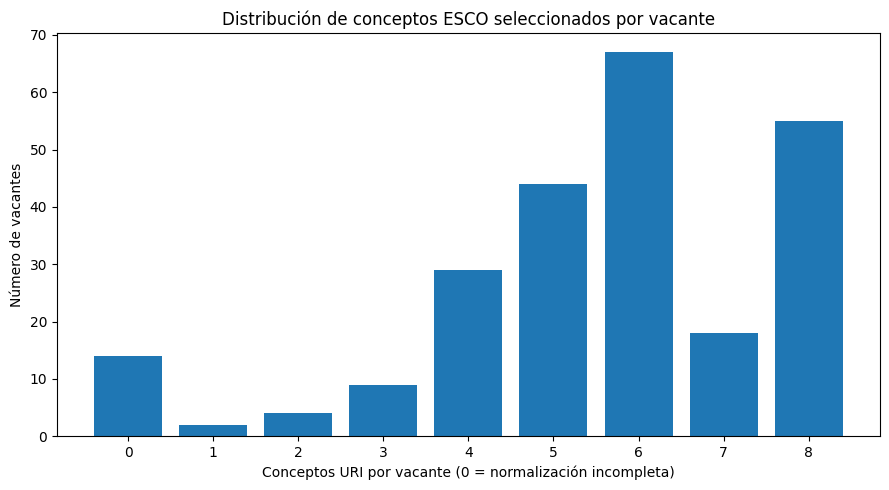

Vacantes con 8 conceptos (tope del normalizador): 55


In [5]:
print('Descripción de competencias por vacante (incluye las 14 incompletas):')
display(base['N_Competencias'].describe().to_frame('N_Competencias'))
print('Descripción únicamente para vacantes normalizadas:')
display(base.loc[base['N_Competencias'] > 0, 'N_Competencias'].describe().to_frame('N_Competencias'))

distribucion = base['N_Competencias'].value_counts().sort_index()
display(distribucion.rename_axis('Competencias').reset_index(name='Vacantes'))
plt.figure(figsize=(9, 5))
plt.bar(distribucion.index.astype(str), distribucion.values)
plt.title('Distribución de conceptos ESCO seleccionados por vacante')
plt.xlabel('Conceptos URI por vacante (0 = normalización incompleta)')
plt.ylabel('Número de vacantes')
plt.tight_layout()
plt.show()
print('Vacantes con 8 conceptos (tope del normalizador):', int(base['N_Competencias'].eq(8).sum()))

## 5. Distribución de vacantes por empresa y ubicación

Las denominaciones se toman **tal cual del dataset**: no se homologan empresas ni se interpreta la ubicación como lugar de residencia. El estudio incluye ofertas mineras de alcance nacional; una vacante ubicada en Santiago u otra región no debe excluirse por ese motivo.

,Empresa,Vacantes
0,R&Q Ingeniería,14
1,Wood,12
2,Enaex,9
3,SGS,9
4,CyD Ingeniería,9
5,Antofagasta Minerals,8
6,J.E.J. INGENIERÍA S.A.,5
7,DRS Ingeniería y Gestión,5
8,Turner & Townsend,5
9,Empresa Confidencial,4


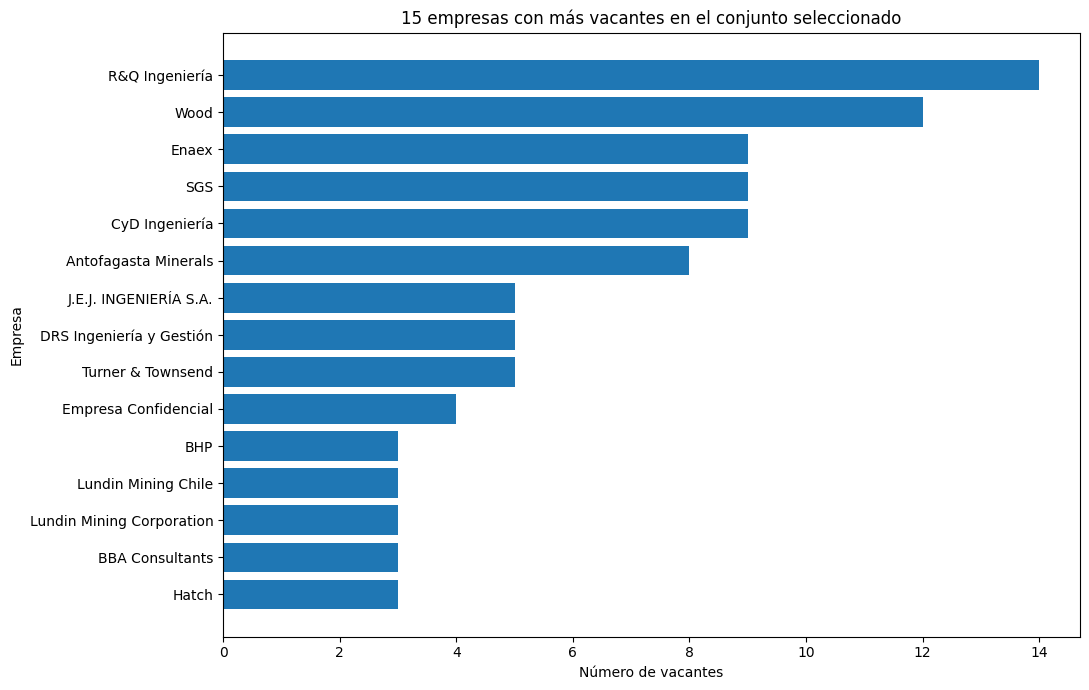

In [6]:
empresas = base['empresa'].value_counts().rename_axis('Empresa').reset_index(name='Vacantes')
display(empresas.head(20))
top_empresas = empresas.head(15).iloc[::-1]
plt.figure(figsize=(11, 7))
plt.barh(top_empresas['Empresa'], top_empresas['Vacantes'])
plt.title('15 empresas con más vacantes en el conjunto seleccionado')
plt.xlabel('Número de vacantes')
plt.ylabel('Empresa')
plt.tight_layout()
plt.show()

,Ubicación declarada,Vacantes
0,"Gran Santiago, Región Metropolitana de Santiago, Chile",77
1,"Antofagasta, Región de Antofagasta, Chile",37
2,Área metropolitana de Santiago,13
3,"Región Metropolitana de Santiago, Chile",11
4,"Calama, Región de Antofagasta, Chile",10
5,"Las Condes, Región Metropolitana de Santiago, Chile",9
6,"Copiapó, Región de Atacama, Chile",8
7,Chile,8
8,"Rancagua, Región del Libertador General Bernardo O'Higgins, Chile",7
9,"Región de Antofagasta, Chile",5


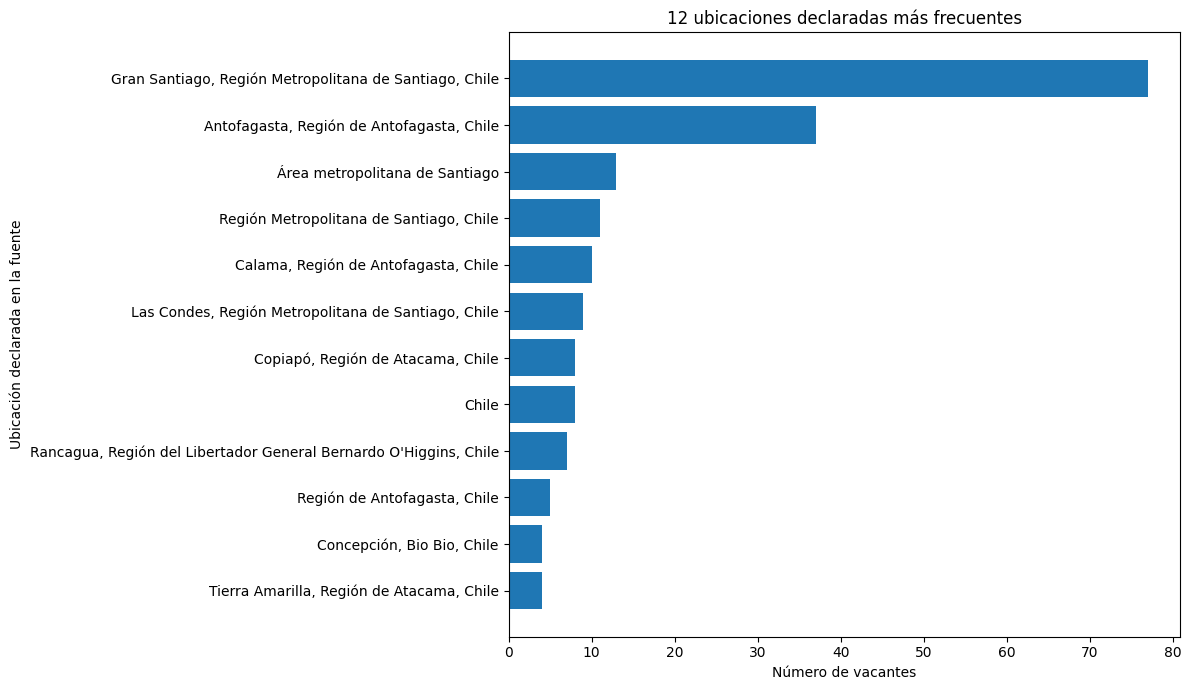

In [7]:
ubicaciones = base['ubicacion'].value_counts().rename_axis('Ubicación declarada').reset_index(name='Vacantes')
display(ubicaciones.head(20))
top_ubicaciones = ubicaciones.head(12).iloc[::-1]
plt.figure(figsize=(12, 7))
plt.barh(top_ubicaciones['Ubicación declarada'], top_ubicaciones['Vacantes'])
plt.title('12 ubicaciones declaradas más frecuentes')
plt.xlabel('Número de vacantes')
plt.ylabel('Ubicación declarada en la fuente')
plt.tight_layout()
plt.show()

## 6. Disciplinas y trayectoria profesional

`disciplina_detectada` puede contener **varias ingenierías en una misma etiqueta**. Aquí se cuenta la clasificación completa que produjo el equipo, sin dividirla ni multiplicar las vacantes. Todas las trayectorias profesionales forman parte del universo de investigación.

,Disciplina declarada,Vacantes
0,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,46
1,INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,31
2,INGENIERÍA CIVIL DE MINAS,20
3,INGENIERÍA CIVIL MECÁNICA / INGENIERÍA MECÁNICA,15
4,INGENIERÍA CIVIL,13
5,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,9
6,INGENIERÍA CIVIL METALÚRGICA / INGENIERÍA METALÚRGICA / INGENIERÍA DE PROCESOS,8
7,"INGENIERÍA CIVIL (Plan común, Estructural u Obras Civiles)",8
8,INGENIERÍA CIVIL QUÍMICA / INGENIERÍA EN QUÍMICA INDUSTRIAL,5
9,INGENIERÍA EN PREVENCIÓN DE RIESGOS Y MEDIOAMBIENTE,5


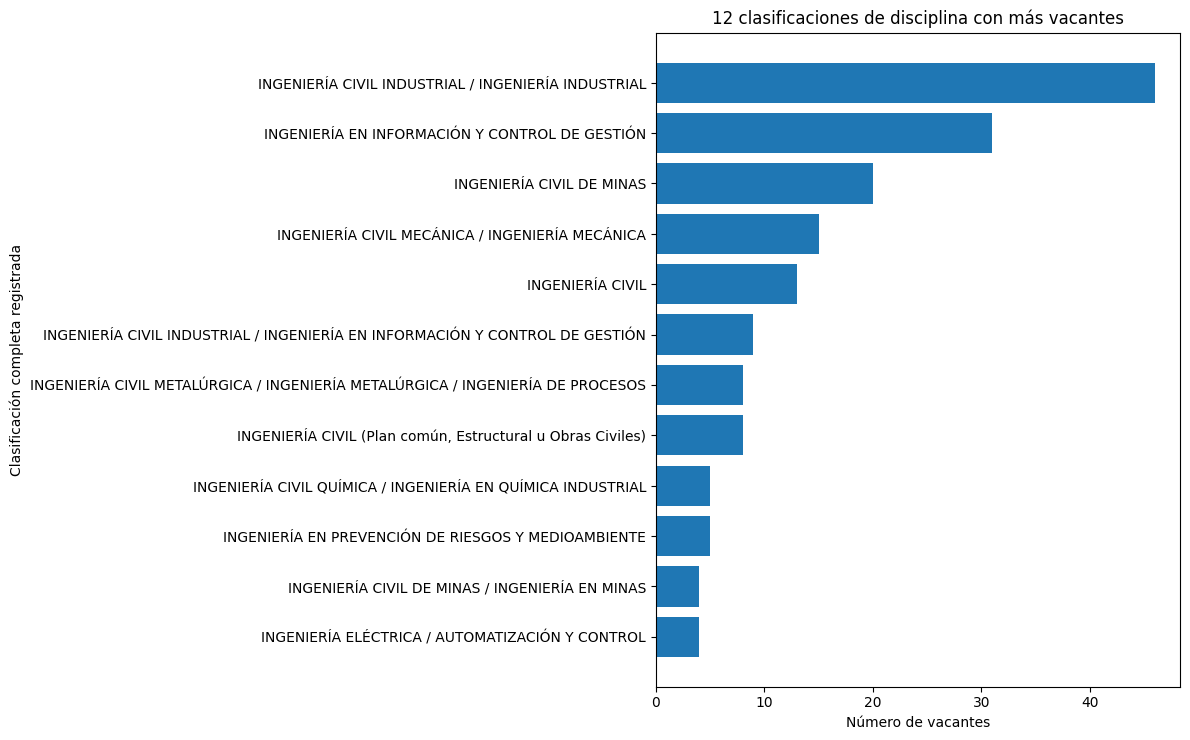

In [8]:
disciplinas = base['disciplina_detectada'].value_counts().rename_axis('Disciplina declarada').reset_index(name='Vacantes')
display(disciplinas.head(20))
top_disciplinas = disciplinas.head(12).iloc[::-1]
plt.figure(figsize=(12, 7.5))
plt.barh(top_disciplinas['Disciplina declarada'], top_disciplinas['Vacantes'])
plt.title('12 clasificaciones de disciplina con más vacantes')
plt.xlabel('Número de vacantes')
plt.ylabel('Clasificación completa registrada')
plt.tight_layout()
plt.show()

,Trayectoria,Vacantes
0,SENIOR_LIDERAZGO,130
1,SEMI_SENIOR,61
2,JUNIOR_TRAINEE,45
3,PRACTICA_MEMORIA,6


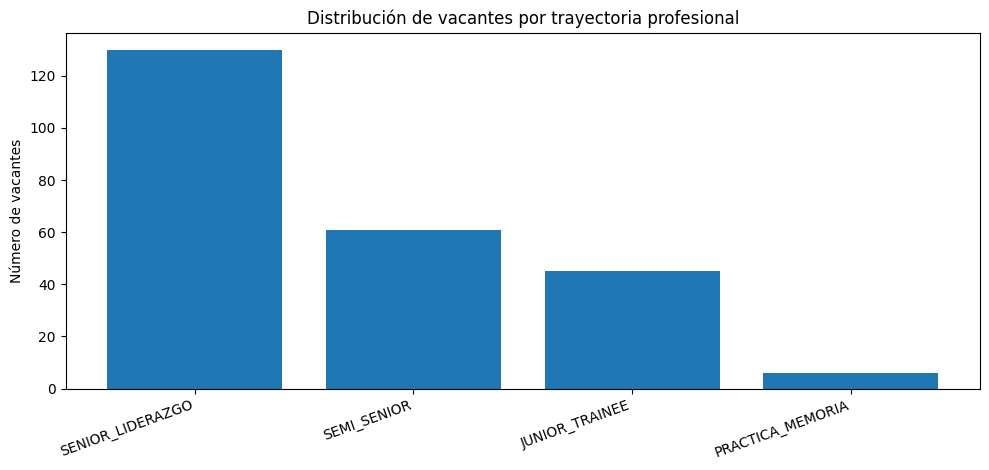

In [9]:
trayectorias = base['categoria_trayectoria'].value_counts().rename_axis('Trayectoria').reset_index(name='Vacantes')
display(trayectorias)
plt.figure(figsize=(10, 4.8))
plt.bar(trayectorias['Trayectoria'], trayectorias['Vacantes'])
plt.ylabel('Número de vacantes')
plt.title('Distribución de vacantes por trayectoria profesional')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 7. Años de experiencia declarados

Se consideran únicamente valores numéricos válidos. Los registros sin dato no se imputan a cero; prácticas, trainee y senior no se convierten automáticamente a un número de años.

Vacantes con años de experiencia numéricos: 237
Vacantes sin años válidos: 5


,Años de experiencia
count,237.000000
mean,5.238397
std,4.115020
min,0.000000
25%,2.000000
50%,5.000000
75%,7.000000
max,25.000000


,Vacantes,Con_experiencia_numerica,Mediana_anios,Promedio_anios
categoria_trayectoria,,,,
SENIOR_LIDERAZGO,130,125,7.0,8.06
SEMI_SENIOR,61,61,3.0,2.88
JUNIOR_TRAINEE,45,45,1.0,1.31
PRACTICA_MEMORIA,6,6,0.0,0.00


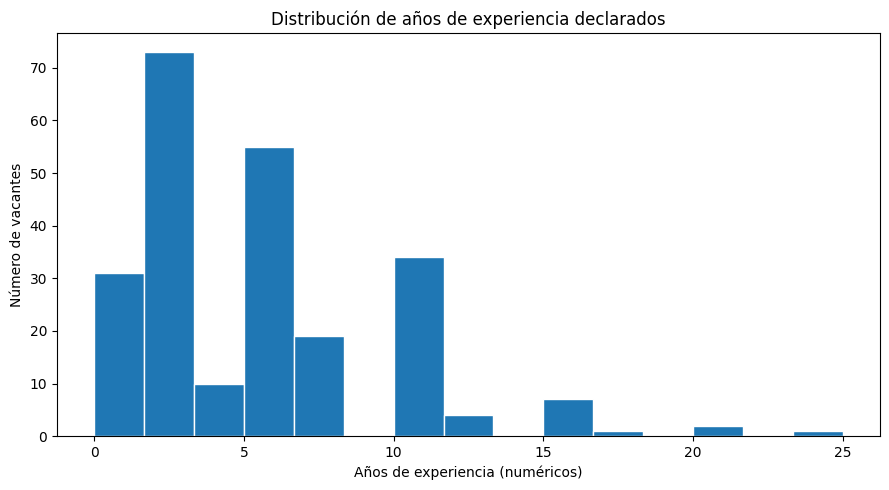

In [10]:
experiencia = base['Anios_Experiencia_Num']
print('Vacantes con años de experiencia numéricos:', int(experiencia.notna().sum()))
print('Vacantes sin años válidos:', int(experiencia.isna().sum()))
display(experiencia.describe().to_frame('Años de experiencia'))
display(base.groupby('categoria_trayectoria').agg(
    Vacantes=('job_id','size'),
    Con_experiencia_numerica=('Anios_Experiencia_Num','count'),
    Mediana_anios=('Anios_Experiencia_Num','median'),
    Promedio_anios=('Anios_Experiencia_Num','mean'),
).round(2).sort_values('Vacantes',ascending=False))

plt.figure(figsize=(9, 5))
plt.hist(experiencia.dropna(), bins=15, edgecolor='white')
plt.title('Distribución de años de experiencia declarados')
plt.xlabel('Años de experiencia (numéricos)')
plt.ylabel('Número de vacantes')
plt.tight_layout()
plt.show()

## 8. Frecuencia de competencias ESCO identificadas

Cada URI se cuenta **una vez por vacante**. Se presentan dos denominadores distintos: 228 vacantes con al menos una selección ESCO y las 242 vacantes del conjunto completo. Ninguno representa una «tasa de cobertura curricular».

In [11]:
n_total = len(base)
n_normalizadas = int((base['N_Competencias'] > 0).sum())
frecuencia = (
    competencias.drop_duplicates(subset=['job_id','URI'])
    .groupby('URI', as_index=False)
    .agg(Competencia=('Competencia','first'), Vacantes=('job_id','nunique'))
    .sort_values(['Vacantes','Competencia'], ascending=[False,True])
    .reset_index(drop=True)
)
frecuencia['Porc_normalizadas'] = (100 * frecuencia['Vacantes'] / n_normalizadas).round(2)
frecuencia['Porc_total'] = (100 * frecuencia['Vacantes'] / n_total).round(2)
print('Conceptos URI únicos:', len(frecuencia))
print('Total de menciones URI-vacante:', len(competencias))
print('Conceptos presentes en una sola vacante:', int(frecuencia['Vacantes'].eq(1).sum()))
print('Conceptos presentes en dos o más vacantes:', int(frecuencia['Vacantes'].ge(2).sum()))
display(frecuencia.head(20))

# Dos URI diferentes pueden compartir la misma etiqueta. No se fusionan.
colisiones = (frecuencia.groupby('Competencia').agg(
    URI_distintos=('URI','nunique'), URIs=('URI', lambda s: ' | '.join(s))
).query('URI_distintos > 1').sort_values('URI_distintos', ascending=False))
print('Etiquetas asociadas a más de un URI:', len(colisiones))
if not colisiones.empty:
    display(colisiones.head(10))

Conceptos URI únicos: 446
Total de menciones URI-vacante: 1341
Conceptos presentes en una sola vacante: 244
Conceptos presentes en dos o más vacantes: 202


,URI,Competencia,Vacantes,Porc_normalizadas,Porc_total
0,http://data.europa.eu/esco/skill/cd5efa8c-e44d-4cbc-91c6-796018dbed68,gestionar proyectos,38,16.67,15.70
1,http://data.europa.eu/esco/skill/a571ae14-3e16-4fd3-a615-5646e0b0b696,analizar datos,33,14.47,13.64
2,http://data.europa.eu/esco/skill/f683ae1d-cb7c-4aa1-b9fe-205e1bd23535,utilizar Microsoft Office,31,13.60,12.81
3,http://data.europa.eu/esco/skill/21c5790c-0930-4d74-b3b0-84caf5af12ea,gestionar presupuestos,26,11.40,10.74
4,http://data.europa.eu/esco/skill/6a899482-8bcf-40ca-ae67-579a1cc467ab,gestionar proyectos de ingeniería,25,10.96,10.33
5,http://data.europa.eu/esco/skill/8dcbcabe-09f7-4d11-940d-125af57bbc40,supervisar indicadores clave de rendimiento,23,10.09,9.50
6,http://data.europa.eu/esco/skill/fbafa41f-cd05-4109-a649-8b44d306d779,crear modelos de datos,20,8.77,8.26
7,http://data.europa.eu/esco/skill/7af6e9e8-1e11-4c0b-b7c6-ac96bbbbc674,coordinar equipos de ingeniería,18,7.89,7.44
8,http://data.europa.eu/esco/skill/a4ec696c-ac73-4bd5-8a3c-09a783cf3944,utilizar software de programación minera,18,7.89,7.44
9,http://data.europa.eu/esco/skill/9d59f4e5-20a5-428e-b8b3-645043500457,crear un ambiente de trabajo de mejora continua,15,6.58,6.20


Etiquetas asociadas a más de un URI: 2


,URI_distintos,URIs
Competencia,,
gestionar contratos,2,http://data.europa.eu/esco/skill/c5646d72-c082-44fd-b47e-c4b0ec59ebbd | http://data.europa.eu/esco/sk...
gestionar recursos humanos,2,http://data.europa.eu/esco/skill/339ac029-066a-4985-9f9d-b3d7c8fea0bb | http://data.europa.eu/esco/sk...


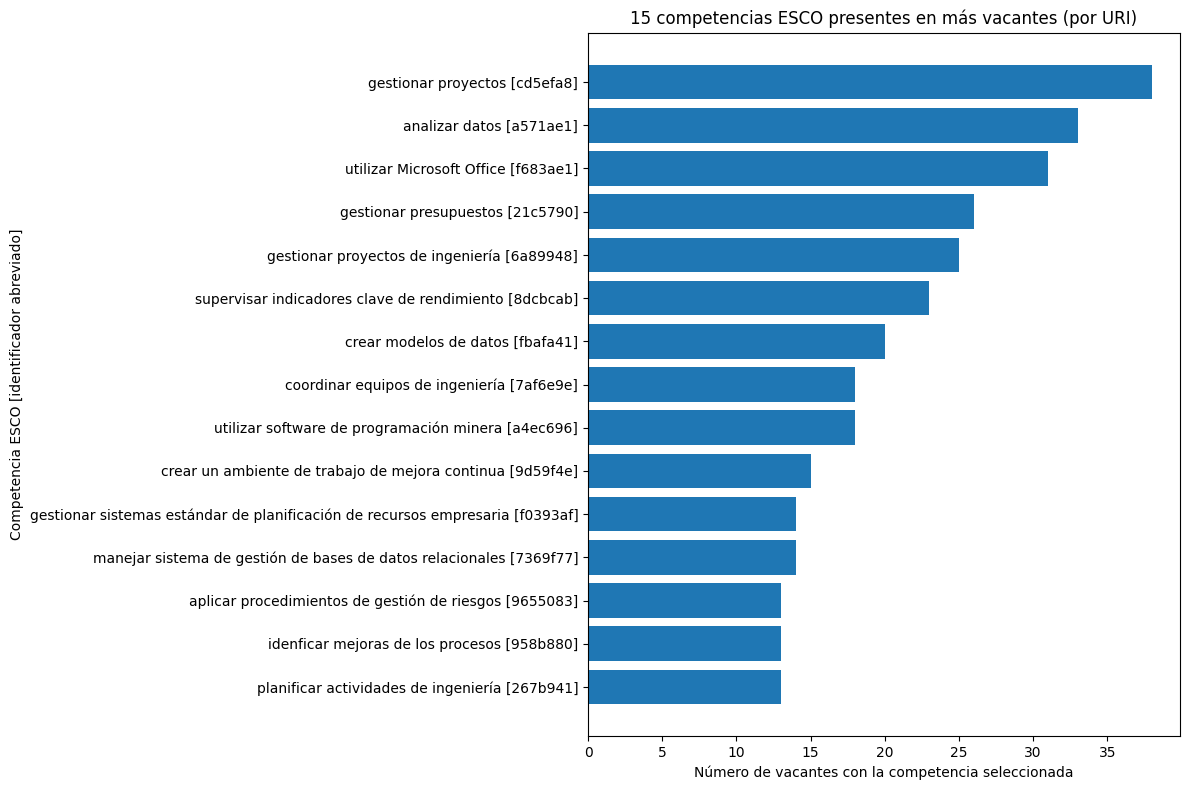

In [12]:
top15 = frecuencia.head(15).iloc[::-1]
etiquetas_grafico = [f"{r.Competencia[:67]} [{r.URI.rsplit('/', 1)[-1][:7]}]" for r in top15.itertuples()]
plt.figure(figsize=(12, 8))
plt.barh(etiquetas_grafico, top15['Vacantes'])
plt.title('15 competencias ESCO presentes en más vacantes (por URI)')
plt.xlabel('Número de vacantes con la competencia seleccionada')
plt.ylabel('Competencia ESCO [identificador abreviado]')
plt.tight_layout()
plt.show()

## 9. Calidad de la normalización por trayectoria

Esta tabla distingue **normalización incompleta**, presencia de competencias y casos que alcanzaron el máximo de ocho. No se excluye ninguna trayectoria de la investigación.

In [13]:
calidad_trayectoria = base.groupby('categoria_trayectoria').agg(
    Vacantes=('job_id','size'),
    Normalizadas=('N_Competencias', lambda s: int(s.gt(0).sum())),
    Incompletas=('N_Competencias', lambda s: int(s.eq(0).sum())),
    Alcanzan_tope_8=('N_Competencias', lambda s: int(s.eq(8).sum())),
    Media_asignaciones=('N_Competencias','mean')
)
calidad_trayectoria['Porc_normalizadas'] = (100*calidad_trayectoria['Normalizadas']/calidad_trayectoria['Vacantes']).round(2)
calidad_trayectoria['Porc_tope_8'] = (100*calidad_trayectoria['Alcanzan_tope_8']/calidad_trayectoria['Vacantes']).round(2)
display(calidad_trayectoria.round(2).sort_values('Vacantes', ascending=False))

,Vacantes,Normalizadas,Incompletas,Alcanzan_tope_8,Media_asignaciones,Porc_normalizadas,Porc_tope_8
categoria_trayectoria,,,,,,,
SENIOR_LIDERAZGO,130,123,7,32,5.70,94.62,24.62
SEMI_SENIOR,61,60,1,15,5.95,98.36,24.59
JUNIOR_TRAINEE,45,41,4,7,4.78,91.11,15.56
PRACTICA_MEMORIA,6,4,2,1,3.67,66.67,16.67


In [14]:
base_normalizada = base[base['N_Competencias'] > 0]
for tray, grupo in competencias.groupby('categoria_trayectoria', sort=True):
    n_vacantes = int(base_normalizada['categoria_trayectoria'].eq(tray).sum())
    top = (grupo.groupby(['URI','Competencia'])['job_id'].nunique()
           .sort_values(ascending=False).head(8).reset_index(name='Vacantes'))
    top['Pct_en_trayectoria_normalizada'] = (100 * top['Vacantes'] / n_vacantes).round(2)
    print(f'\n{tray} — {n_vacantes} vacantes con selección ESCO')
    display(top[['Competencia','URI','Vacantes','Pct_en_trayectoria_normalizada']])


JUNIOR_TRAINEE — 41 vacantes con selección ESCO


,Competencia,URI,Vacantes,Pct_en_trayectoria_normalizada
0,analizar datos,http://data.europa.eu/esco/skill/a571ae14-3e16-4fd3-a615-5646e0b0b696,10,24.39
1,supervisar indicadores clave de rendimiento,http://data.europa.eu/esco/skill/8dcbcabe-09f7-4d11-940d-125af57bbc40,10,24.39
2,gestionar proyectos,http://data.europa.eu/esco/skill/cd5efa8c-e44d-4cbc-91c6-796018dbed68,10,24.39
3,utilizar Microsoft Office,http://data.europa.eu/esco/skill/f683ae1d-cb7c-4aa1-b9fe-205e1bd23535,7,17.07
4,crear un ambiente de trabajo de mejora continua,http://data.europa.eu/esco/skill/9d59f4e5-20a5-428e-b8b3-645043500457,5,12.20
5,gestionar presupuestos,http://data.europa.eu/esco/skill/21c5790c-0930-4d74-b3b0-84caf5af12ea,4,9.76
6,utilizar programas informáticos específicos para el análisis de datos,http://data.europa.eu/esco/skill/c95c29fe-3971-46b7-80e9-1f7e75ba99b3,4,9.76
7,idenficar mejoras de los procesos,http://data.europa.eu/esco/skill/958b8802-ec3e-4813-97f7-6c8f48610dbd,4,9.76



PRACTICA_MEMORIA — 4 vacantes con selección ESCO


,Competencia,URI,Vacantes,Pct_en_trayectoria_normalizada
0,utilizar Microsoft Office,http://data.europa.eu/esco/skill/f683ae1d-cb7c-4aa1-b9fe-205e1bd23535,3,75.0
1,comunicar las medidas de salud y seguridad,http://data.europa.eu/esco/skill/0cfc7eb9-2891-4153-b335-6331f381ff05,1,25.0
2,garantizar el cumplimiento de la legislación en materia de seguridad,http://data.europa.eu/esco/skill/233be639-bdb5-4099-ab40-96d537d6c1f3,1,25.0
3,gestionar la información de proyectos,http://data.europa.eu/esco/skill/22902bf9-cc3f-495b-811a-c441e28e23f6,1,25.0
4,seleccionar el control de riesgos,http://data.europa.eu/esco/skill/2399e65b-cf2b-4f5b-9002-607e790fcf2a,1,25.0
5,aplicar medidas correctivas,http://data.europa.eu/esco/skill/286e486c-a094-4715-8e5b-a2370b09a408,1,25.0
6,elaborar una evaluación de riesgos,http://data.europa.eu/esco/skill/594bd121-9614-4e87-9ecf-6ccb95507efe,1,25.0
7,realizar inspecciones,http://data.europa.eu/esco/skill/36e9c099-614e-44f1-ab0a-5e6fda4a0763,1,25.0



SEMI_SENIOR — 60 vacantes con selección ESCO


,Competencia,URI,Vacantes,Pct_en_trayectoria_normalizada
0,analizar datos,http://data.europa.eu/esco/skill/a571ae14-3e16-4fd3-a615-5646e0b0b696,13,21.67
1,crear modelos de datos,http://data.europa.eu/esco/skill/fbafa41f-cd05-4109-a649-8b44d306d779,11,18.33
2,aplicar procesos de calidad de datos,http://data.europa.eu/esco/skill/713fb616-118e-40bc-9366-4a69879a49d5,7,11.67
3,manejar sistema de gestión de bases de datos relacionales,http://data.europa.eu/esco/skill/7369f779-4b71-4aab-8836-48b69c676eec,7,11.67
4,utilizar Microsoft Office,http://data.europa.eu/esco/skill/f683ae1d-cb7c-4aa1-b9fe-205e1bd23535,7,11.67
5,automatizar tareas en la nube,http://data.europa.eu/esco/skill/ce8ae6ca-61d8-4174-b457-641de96cbff4,6,10.00
6,supervisar indicadores clave de rendimiento,http://data.europa.eu/esco/skill/8dcbcabe-09f7-4d11-940d-125af57bbc40,6,10.00
7,idenficar mejoras de los procesos,http://data.europa.eu/esco/skill/958b8802-ec3e-4813-97f7-6c8f48610dbd,5,8.33



SENIOR_LIDERAZGO — 123 vacantes con selección ESCO


,Competencia,URI,Vacantes,Pct_en_trayectoria_normalizada
0,gestionar proyectos,http://data.europa.eu/esco/skill/cd5efa8c-e44d-4cbc-91c6-796018dbed68,24,19.51
1,gestionar presupuestos,http://data.europa.eu/esco/skill/21c5790c-0930-4d74-b3b0-84caf5af12ea,20,16.26
2,gestionar proyectos de ingeniería,http://data.europa.eu/esco/skill/6a899482-8bcf-40ca-ae67-579a1cc467ab,19,15.45
3,coordinar equipos de ingeniería,http://data.europa.eu/esco/skill/7af6e9e8-1e11-4c0b-b7c6-ac96bbbbc674,14,11.38
4,utilizar software de programación minera,http://data.europa.eu/esco/skill/a4ec696c-ac73-4bd5-8a3c-09a783cf3944,14,11.38
5,utilizar Microsoft Office,http://data.europa.eu/esco/skill/f683ae1d-cb7c-4aa1-b9fe-205e1bd23535,14,11.38
6,analizar datos,http://data.europa.eu/esco/skill/a571ae14-3e16-4fd3-a615-5646e0b0b696,10,8.13
7,aplicar procedimientos de gestión de riesgos,http://data.europa.eu/esco/skill/96550830-539b-4746-96aa-92aa4959945d,10,8.13


## 10. Exploración de similitud descriptiva entre disciplinas

Para reproducir el carácter comparativo de `EDA_Perfiles.ipynb`, se utiliza Jaccard sobre **conjuntos de URI identificados** en las disciplinas más representadas. Este índice expresa **solapamiento de conceptos extraídos** entre grupos de vacantes, no similitud real de puestos, equivalencia profesional ni porcentaje de cobertura. Las disciplinas con más vacantes pueden acumular más conceptos; los resultados deben interpretarse considerando el tamaño de cada grupo.

,Disciplina A,Disciplina B,Vacantes A con ESCO,Vacantes B con ESCO,URI compartidos,Jaccard URI (%)
15,INGENIERÍA CIVIL MECÁNICA / INGENIERÍA MECÁNICA,INGENIERÍA CIVIL,15,11,15,16.85
9,INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,29,9,15,15.79
19,INGENIERÍA CIVIL,"INGENIERÍA CIVIL (Plan común, Estructural u Obras Civiles)",11,8,11,14.86
3,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,INGENIERÍA CIVIL,46,11,24,14.81
17,INGENIERÍA CIVIL MECÁNICA / INGENIERÍA MECÁNICA,"INGENIERÍA CIVIL (Plan común, Estructural u Obras Civiles)",15,8,12,14.46
0,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,46,29,26,13.90
12,INGENIERÍA CIVIL DE MINAS,INGENIERÍA CIVIL,20,11,15,13.51
2,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,INGENIERÍA CIVIL MECÁNICA / INGENIERÍA MECÁNICA,46,15,23,13.29
1,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,INGENIERÍA CIVIL DE MINAS,46,20,25,12.95
4,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,46,9,20,12.90


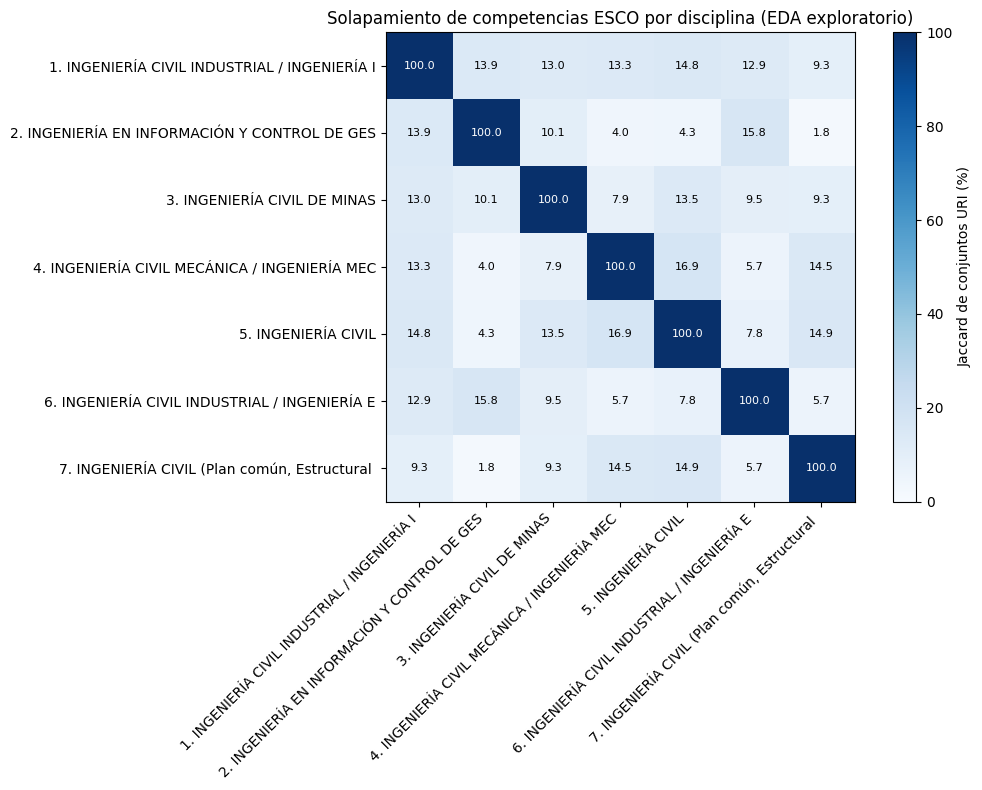

Disciplinas incluidas:


,Vacantes normalizadas
disciplina_detectada,
INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA INDUSTRIAL,46
INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,29
INGENIERÍA CIVIL DE MINAS,20
INGENIERÍA CIVIL MECÁNICA / INGENIERÍA MECÁNICA,15
INGENIERÍA CIVIL,11
INGENIERÍA CIVIL INDUSTRIAL / INGENIERÍA EN INFORMACIÓN Y CONTROL DE GESTIÓN,9
"INGENIERÍA CIVIL (Plan común, Estructural u Obras Civiles)",8


In [15]:
from itertools import combinations

TOP_N_DISCIPLINAS = 7
conteo_disc_normalizadas = (base_normalizada['disciplina_detectada']
                            .value_counts().head(TOP_N_DISCIPLINAS))
grupos = list(conteo_disc_normalizadas.index)
conjuntos = {disc: set(competencias.loc[
    competencias['disciplina_detectada'].eq(disc), 'URI']) for disc in grupos}

def jaccard_pct(a, b):
    union = a | b
    return 100.0 * len(a & b) / len(union) if union else np.nan

comparaciones = []
for a, b in combinations(grupos, 2):
    comparaciones.append({
        'Disciplina A': a, 'Disciplina B': b,
        'Vacantes A con ESCO': int(conteo_disc_normalizadas[a]),
        'Vacantes B con ESCO': int(conteo_disc_normalizadas[b]),
        'URI compartidos': len(conjuntos[a] & conjuntos[b]),
        'Jaccard URI (%)': round(jaccard_pct(conjuntos[a], conjuntos[b]), 2),
    })
comparacion = pd.DataFrame(comparaciones).sort_values('Jaccard URI (%)', ascending=False)
display(comparacion.head(15))

matriz = np.array([[jaccard_pct(conjuntos[a], conjuntos[b]) for b in grupos] for a in grupos])
etiquetas = [f'{i+1}. {g[:42]}' for i,g in enumerate(grupos)]
plt.figure(figsize=(11, 8))
plt.imshow(matriz, vmin=0, vmax=100, cmap='Blues')
plt.xticks(range(len(grupos)), etiquetas, rotation=45, ha='right')
plt.yticks(range(len(grupos)), etiquetas)
for i in range(len(grupos)):
    for j in range(len(grupos)):
        plt.text(j, i, f'{matriz[i,j]:.1f}', ha='center', va='center',
                 color='white' if matriz[i,j] > 55 else 'black', fontsize=8)
plt.colorbar(label='Jaccard de conjuntos URI (%)')
plt.title('Solapamiento de competencias ESCO por disciplina (EDA exploratorio)')
plt.tight_layout()
plt.show()
print('Disciplinas incluidas:')
display(conteo_disc_normalizadas.rename('Vacantes normalizadas').to_frame())

## 11. Explorador de una oferta individual

Cambia el valor de `job_id_ejemplo` para inspeccionar cualquier registro sin alterar datos. Se muestran **URI, etiquetas y evidencias**. No se vuelve a consultar Qwen ni se genera información nueva.

In [16]:
job_id_ejemplo = base.iloc[0]['job_id']  # reemplazar por otro job_id para consultar
seleccion = base.loc[base['job_id'].eq(job_id_ejemplo)]
if seleccion.empty:
    print('No se encontró el job_id:', job_id_ejemplo)
else:
    columnas_ficha = ['job_id','titulo','empresa','ubicacion','disciplina_detectada',
                      'categoria_trayectoria','anios_experiencia','Estado_ESCO',
                      'Estado_Analitico','N_Competencias']
    display(seleccion[columnas_ficha].T.rename(columns={seleccion.index[0]: 'Valor'}))
    detalles_oferta = competencias.loc[competencias['job_id'].eq(job_id_ejemplo),
                                      ['Competencia','URI','Evidencia']]
    if detalles_oferta.empty:
        print('Normalización incompleta: no hay competencias ESCO seleccionadas.')
    else:
        display(detalles_oferta.reset_index(drop=True))

,Valor
job_id,afe7fc2465345541
titulo,Puestos vacantes: Supervisora(or) Tronadura (20684)
empresa,Antofagasta Minerals
ubicacion,"Gran Santiago, Región Metropolitana de Santiago, Chile"
disciplina_detectada,INGENIERÍA CIVIL DE MINAS
categoria_trayectoria,SENIOR_LIDERAZGO
anios_experiencia,3
Estado_ESCO,Catalogo_verificado_revision_pendiente
Estado_Analitico,Con selección ESCO
N_Competencias,8


,Competencia,URI,Evidencia
0,insertar cargas en pozos de perforación,http://data.europa.eu/esco/skill/1be014ca-6909-497a-95fc-426ef9945583,Supervisar la correcta ejecución del proceso de carguío de explosivo y tronadura según los diseños y ...
1,detonar explosivos en condiciones seguras,http://data.europa.eu/esco/skill/c42a92b2-a802-4cf6-a645-3904004bbdbe,"Verificar el cumplimiento de los procedimientos de seguridad antes, durante y después de la tronadura."
2,examinar zonas tras la detonación de explosivos,http://data.europa.eu/esco/skill/e9867780-9584-43a9-af10-8eb730b525cc,Realizar inspecciones post-tronadura para evaluar resultados y proponer mejoras.
3,gestionar el inventario,http://data.europa.eu/esco/skill/ab6265f2-a9bf-49e8-a9a5-67cbab4de38b,"Llevar el control del consumo de explosivos, accesorios y materiales auxiliares."
4,presentar informes,http://data.europa.eu/esco/skill/d0f2f8a7-d935-4a6d-8e54-dcc3e5e2cbeb,Elaborar informes diarios de operación de tronadura y cumplimiento de plan.
5,colaborar con profesionales de la geología,http://data.europa.eu/esco/skill/56fa904b-eb1c-4f34-a671-8c5dc6af6de1,Coordinar con el área de geología los tiempos de operación de muestreo para liberación de áreas de tr...
6,mantener la relación con los proveedores,http://data.europa.eu/esco/skill/3cd35f5d-ce6d-4f14-9a09-53d7a28d834c,Asegurar la disponibilidad de materiales explosivos y equipos necesarios con proveedor de explosivo d...
7,crear un ambiente de trabajo de mejora continua,http://data.europa.eu/esco/skill/9d59f4e5-20a5-428e-b8b3-645043500457,Realizar inspecciones post-tronadura para evaluar resultados y proponer mejoras.


## 12. Trazabilidad de la selección de vacantes

Este control conecta el EDA con el archivo **`Obj1/Ofertas/dataset_competencias_clasificado.json`**. El conjunto inicialmente evaluado contiene **252** ofertas y **242** se clasificaron como pertinentes para el universo de análisis. La diferencia (**10**) corresponde a registros no seleccionados en esa clasificación; no debe confundirse con las **14** vacantes seleccionadas cuya normalización ESCO quedó incompleta.

La clasificación y las consultas empleadas para obtener las ofertas pueden introducir sesgos de cobertura. El conjunto refleja las vacantes efectivamente recopiladas y seleccionadas, **no una muestra estadísticamente representativa de toda la demanda minera nacional**. La comparación con programas educativos de Coquimbo no requiere restringir las ofertas laborales a esa región.

In [ ]:
# Esta celda complementa el CSV ESCO con metadatos de la selección original.
# No modifica la base laboral ni las competencias normalizadas.
import json
from pathlib import Path
from urllib.parse import urlparse

json_relativo = Path('Obj1/Ofertas/dataset_competencias_clasificado.json')
raices_posibles = [Path.cwd(), *list(Path.cwd().parents)[:5]]
rutas_json = []
for raiz in raices_posibles:
    rutas_json.extend([raiz/json_relativo, raiz/'DESARROLLO'/json_relativo])
ruta_json = next((p for p in rutas_json if p.is_file()), None)

if ruta_json is None:
    print('No se encontró el JSON de Obj1/Ofertas. El EDA ESCO anterior sigue siendo válido;')
    print('para revisar selección y fechas, añade ese archivo al proyecto y vuelve a ejecutar esta celda.')
    datos_origen = None
else:
    datos_origen = json.loads(ruta_json.read_text(encoding='utf-8-sig'))
    metadata = datos_origen.get('metadata', {})
    filas_origen = datos_origen['ofertas_ingenieria']
    origen = pd.DataFrame(filas_origen)
    n_evaluadas = int(metadata.get('total_ofertas_evaluadas', len(origen)))
    n_seleccionadas = int(metadata.get('total_ofertas_ingenieria', len(origen)))
    n_excluidas = n_evaluadas - n_seleccionadas
    assert n_excluidas >= 0, 'Conteos inconsistentes en metadatos de selección'
    assert len(origen) == len(base) == n_seleccionadas, 'Número de ofertas distinto entre Obj1 y Obj2'
    assert set(origen['job_id']) == set(base['job_id']), 'Los job_id de Obj1 y Obj2 no coinciden'
    print('Fuente de selección:', ruta_json)
    display(pd.DataFrame({
        'Etapa':['Ofertas evaluadas','Ofertas seleccionadas','Ofertas no seleccionadas',
                 'Seleccionadas con ESCO','Seleccionadas con normalización incompleta'],
        'Vacantes':[n_evaluadas,n_seleccionadas,n_excluidas,
                    int(base['N_Competencias'].gt(0).sum()),int(base['N_Competencias'].eq(0).sum())],
        'Interpretación':['Universo inicialmente clasificado','Universo del estudio',
                          'Exclusiones del proceso de clasificación','Subconjunto con URI seleccionados',
                          'No significa que la oferta carezca de habilidades']
    }))
    dominios = origen['url_base'].astype(str).map(lambda s: urlparse(s).netloc)
    print('Dominios de las fuentes recopiladas:')
    display(dominios.value_counts().rename_axis('Dominio').reset_index(name='Ofertas'))

## 13. Dimensión temporal disponible (exploratoria)

La fuente de `Obj1/Ofertas` conserva `fecha_declarada` (texto de la publicación) y `fecha_estimada_iso` (fecha inferida a partir de esa referencia). Se muestra la distribución de estas **fechas estimadas**, sin tratarlas como fechas verificadas o como una serie histórica representativa de evolución del empleo minero.

Las ofertas proceden de un proceso de recopilación en una ventana temporal concreta: una alta concentración en un mes puede reflejar **cuándo se capturaron las publicaciones** y cómo se interpretaron expresiones relativas como «Hace 1 semana», no necesariamente cambios de la demanda. No extrapolar tendencias a otros meses ni confundir la fecha estimada con vigencia de la vacante.

In [ ]:
if datos_origen is None:
    print('Análisis temporal no disponible: requiere Obj1/Ofertas/dataset_competencias_clasificado.json')
else:
    temporal = origen[['job_id','fecha_declarada','fecha_estimada_iso']].copy()
    temporal['Fecha_estimada'] = pd.to_datetime(temporal['fecha_estimada_iso'], errors='coerce')
    temporal = temporal.merge(base[['job_id','Estado_Analitico']], on='job_id', how='left', validate='one_to_one')
    print('Ofertas con fecha estimada interpretable:', int(temporal['Fecha_estimada'].notna().sum()))
    print('Ofertas sin fecha estimada interpretable:', int(temporal['Fecha_estimada'].isna().sum()))
    print('Fecha estimada mínima:', temporal['Fecha_estimada'].min())
    print('Fecha estimada máxima:', temporal['Fecha_estimada'].max())
    distribucion_mensual = (temporal.dropna(subset=['Fecha_estimada'])
                          .assign(Mes=lambda x: x['Fecha_estimada'].dt.to_period('M').astype(str))
                          .groupby('Mes', as_index=False).agg(Vacantes=('job_id','nunique')))
    display(distribucion_mensual)
    if not distribucion_mensual.empty:
        plt.figure(figsize=(10,4.5))
        plt.bar(distribucion_mensual['Mes'], distribucion_mensual['Vacantes'])
        plt.title('Ofertas por mes de fecha estimada (no equivale a evolución de la demanda)')
        plt.xlabel('Mes de fecha estimada')
        plt.ylabel('Vacantes recopiladas')
        plt.xticks(rotation=35, ha='right')
        plt.tight_layout()
        plt.show()
    print('Advertencia: fechas inferidas de referencias relativas; interpretación descriptiva solamente.')

## 14. Resumen de controles e interpretación para la tesis

El EDA caracteriza el conjunto laboral **sin incorporar hipótesis de ausencia de competencias**. Los resultados dependen de la selección automatizada basada en texto, un catálogo ESCO específico y un máximo de ocho conceptos por vacante.

- **Unidad y alcance:** una vacante por `job_id`, de alcance nacional y con todas las trayectorias previstas en el estudio.
- **Identificación:** una competencia se contabiliza mediante su **URI ESCO**, preservando su etiqueta oficial y la evidencia registrada.
- **Normalización incompleta:** si no se seleccionaron competencias, el registro se mantiene en la población pero no se usa para calcular frecuencias entre vacantes normalizadas; se informan ambos denominadores cuando corresponda.
- **Sesgo de selección:** las frecuencias describen competencias **detectadas automáticamente**, no la totalidad de habilidades requeridas por el mercado.
- **Límite por vacante:** los resultados están condicionados por el máximo de ocho; evaluar su sensibilidad corresponde a la etapa metodológica siguiente.
- **Siguiente actividad:** clustering y reglas de asociación por URI sobre conjuntos definidos; **OB4** distinguirá presencia documental de cobertura formativa real.

**Este notebook no sobrescribe ni genera CSV derivados por defecto:** puede ejecutarse íntegramente mediante *Run All* en Jupyter o VS Code, conservando como entrada el archivo de `Obj2/Act. 1`.